In [3]:
import os

project_path = "/Users/bassma/Downloads/MedMentor"
os.chdir(project_path)

print("Now working in:")
print(os.getcwd())

print("\nFiles/folders here:")
print(os.listdir())

Now working in:
/Users/bassma/Downloads/MedMentor

Files/folders here:
['.DS_Store', 'app', 'dataset', 'models', 'results', 'notebooks']


In [5]:
from pathlib import Path
import os

dataset_root = Path("/Users/bassma/Downloads/MedMentor/dataset")
valid_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def count_images_in_split(split_path):
    counts = {}
    total = 0

    if not split_path.exists():
        print(f"{split_path} does not exist")
        return counts, total

    for class_name in sorted(os.listdir(split_path)):
        class_path = split_path / class_name

        if class_name.startswith(".") or not class_path.is_dir():
            continue

        image_count = 0
        for file_name in os.listdir(class_path):
            file_path = class_path / file_name
            if file_name.startswith("."):
                continue
            if file_path.is_file() and file_path.suffix.lower() in valid_exts:
                image_count += 1

        counts[class_name] = image_count
        total += image_count

    return counts, total

for split_name in ["Train", "Validation", "Test"]:
    split_path = dataset_root / split_name
    print(f"\n===== {split_name} =====")

    counts, total = count_images_in_split(split_path)

    for class_name, count in counts.items():
        print(f"{class_name}: {count}")

    print(f"TOTAL {split_name}: {total}")


===== Train =====
actinic keratosis: 114
basal cell carcinoma: 376
dermatofibroma: 95
melanoma: 438
nevus: 357
pigmented benign keratosis: 462
seborrheic keratosis: 77
squamous cell carcinoma: 181
vascular lesion: 139
TOTAL Train: 2239

===== Validation =====
actinic keratosis: 114
basal cell carcinoma: 376
dermatofibroma: 95
melanoma: 438
nevus: 357
pigmented benign keratosis: 462
seborrheic keratosis: 77
squamous cell carcinoma: 181
vascular lesion: 139
TOTAL Validation: 2239

===== Test =====
actinic keratosis: 16
basal cell carcinoma: 16
dermatofibroma: 16
melanoma: 16
nevus: 16
pigmented benign keratosis: 16
seborrheic keratosis: 3
squamous cell carcinoma: 16
vascular lesion: 3
TOTAL Test: 118


In [7]:
import sklearn
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.5.1


In [9]:
from pathlib import Path
import os
from collections import Counter

dataset_root = Path("/Users/bassma/Downloads/MedMentor/dataset")

source_splits = ["Train", "Test"]
valid_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

all_image_paths = []
all_labels = []

for split_name in source_splits:
    split_path = dataset_root / split_name
    print(f"\nChecking split: {split_name}")
    
    if not split_path.exists():
        print(f"Folder not found: {split_path}")
        continue
    
    for class_name in sorted(os.listdir(split_path)):
        class_path = split_path / class_name
        
        if class_name.startswith(".") or not class_path.is_dir():
            continue
        
        added_for_this_class = 0
        
        for file_name in os.listdir(class_path):
            file_path = class_path / file_name
            
            if file_name.startswith("."):
                continue
            if not file_path.is_file():
                continue
            if file_path.suffix.lower() not in valid_exts:
                continue
            
            all_image_paths.append(str(file_path))
            all_labels.append(class_name)
            added_for_this_class += 1
        
        print(f"{class_name}: added {added_for_this_class} images")

print("\n===== COMBINED DATA SUMMARY =====")
print("Total images collected:", len(all_image_paths))
print("Total labels collected:", len(all_labels))

class_counts = Counter(all_labels)
print("\nImages per class after combining Train + Test:")
for class_name, count in sorted(class_counts.items()):
    print(f"{class_name}: {count}")


Checking split: Train
actinic keratosis: added 114 images
basal cell carcinoma: added 376 images
dermatofibroma: added 95 images
melanoma: added 438 images
nevus: added 357 images
pigmented benign keratosis: added 462 images
seborrheic keratosis: added 77 images
squamous cell carcinoma: added 181 images
vascular lesion: added 139 images

Checking split: Test
actinic keratosis: added 16 images
basal cell carcinoma: added 16 images
dermatofibroma: added 16 images
melanoma: added 16 images
nevus: added 16 images
pigmented benign keratosis: added 16 images
seborrheic keratosis: added 3 images
squamous cell carcinoma: added 16 images
vascular lesion: added 3 images

===== COMBINED DATA SUMMARY =====
Total images collected: 2357
Total labels collected: 2357

Images per class after combining Train + Test:
actinic keratosis: 130
basal cell carcinoma: 392
dermatofibroma: 111
melanoma: 454
nevus: 373
pigmented benign keratosis: 478
seborrheic keratosis: 80
squamous cell carcinoma: 197
vascular 

In [11]:
from sklearn.model_selection import train_test_split
from collections import Counter

# Step 1: split into train (70%) and temp (30%)
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    all_image_paths,
    all_labels,
    test_size=0.30,
    stratify=all_labels,
    random_state=42
)

# Step 2: split temp into val (15%) and test (15%)
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    stratify=temp_labels,
    random_state=42
)

print("===== SPLIT SIZES =====")
print("Train:", len(train_paths))
print("Validation:", len(val_paths))
print("Test:", len(test_paths))
print("Total:", len(train_paths) + len(val_paths) + len(test_paths))

print("\n===== TRAIN CLASS COUNTS =====")
for class_name, count in sorted(Counter(train_labels).items()):
    print(f"{class_name}: {count}")

print("\n===== VALIDATION CLASS COUNTS =====")
for class_name, count in sorted(Counter(val_labels).items()):
    print(f"{class_name}: {count}")

print("\n===== TEST CLASS COUNTS =====")
for class_name, count in sorted(Counter(test_labels).items()):
    print(f"{class_name}: {count}")

===== SPLIT SIZES =====
Train: 1649
Validation: 354
Test: 354
Total: 2357

===== TRAIN CLASS COUNTS =====
actinic keratosis: 91
basal cell carcinoma: 274
dermatofibroma: 78
melanoma: 318
nevus: 261
pigmented benign keratosis: 334
seborrheic keratosis: 56
squamous cell carcinoma: 138
vascular lesion: 99

===== VALIDATION CLASS COUNTS =====
actinic keratosis: 19
basal cell carcinoma: 59
dermatofibroma: 17
melanoma: 68
nevus: 56
pigmented benign keratosis: 72
seborrheic keratosis: 12
squamous cell carcinoma: 29
vascular lesion: 22

===== TEST CLASS COUNTS =====
actinic keratosis: 20
basal cell carcinoma: 59
dermatofibroma: 16
melanoma: 68
nevus: 56
pigmented benign keratosis: 72
seborrheic keratosis: 12
squamous cell carcinoma: 30
vascular lesion: 21


In [13]:
import shutil
from pathlib import Path

# New split output folder
split_root = Path("/Users/bassma/Downloads/MedMentor/dataset_split")

# Class names from the combined labels
class_names = sorted(set(all_labels))

# Create main split folders and class subfolders
for split_name in ["train", "val", "test"]:
    for class_name in class_names:
        folder_path = split_root / split_name / class_name
        folder_path.mkdir(parents=True, exist_ok=True)

print("Folder structure created successfully.")

# Helper function to copy files into the correct class folder
def copy_files(image_paths, labels, split_name):
    copied_count = 0
    
    for src_path, label in zip(image_paths, labels):
        src = Path(src_path)
        dst = split_root / split_name / label / src.name
        shutil.copy2(src, dst)
        copied_count += 1
    
    print(f"{split_name}: copied {copied_count} images")

# Copy each split
copy_files(train_paths, train_labels, "train")
copy_files(val_paths, val_labels, "val")
copy_files(test_paths, test_labels, "test")

print("\nDone. New dataset split created at:")
print(split_root)

Folder structure created successfully.
train: copied 1649 images
val: copied 354 images
test: copied 354 images

Done. New dataset split created at:
/Users/bassma/Downloads/MedMentor/dataset_split


In [15]:
from pathlib import Path
import os

split_root = Path("/Users/bassma/Downloads/MedMentor/dataset_split")
valid_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def count_images_in_split(split_path):
    counts = {}
    total = 0

    for class_name in sorted(os.listdir(split_path)):
        class_path = split_path / class_name

        if class_name.startswith(".") or not class_path.is_dir():
            continue

        image_count = 0
        for file_name in os.listdir(class_path):
            file_path = class_path / file_name
            if file_name.startswith("."):
                continue
            if file_path.is_file() and file_path.suffix.lower() in valid_exts:
                image_count += 1

        counts[class_name] = image_count
        total += image_count

    return counts, total

for split_name in ["train", "val", "test"]:
    split_path = split_root / split_name
    print(f"\n===== {split_name.upper()} =====")

    counts, total = count_images_in_split(split_path)

    for class_name, count in counts.items():
        print(f"{class_name}: {count}")

    print(f"TOTAL {split_name}: {total}")


===== TRAIN =====
actinic keratosis: 91
basal cell carcinoma: 274
dermatofibroma: 78
melanoma: 318
nevus: 261
pigmented benign keratosis: 334
seborrheic keratosis: 56
squamous cell carcinoma: 138
vascular lesion: 99
TOTAL train: 1649

===== VAL =====
actinic keratosis: 19
basal cell carcinoma: 59
dermatofibroma: 17
melanoma: 68
nevus: 56
pigmented benign keratosis: 72
seborrheic keratosis: 12
squamous cell carcinoma: 29
vascular lesion: 22
TOTAL val: 354

===== TEST =====
actinic keratosis: 20
basal cell carcinoma: 59
dermatofibroma: 16
melanoma: 68
nevus: 56
pigmented benign keratosis: 72
seborrheic keratosis: 12
squamous cell carcinoma: 30
vascular lesion: 21
TOTAL test: 354


In [17]:
import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device being used:", device)

PyTorch version: 2.11.0
Torchvision version: 0.26.0
Device being used: cpu


In [19]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Path to the new clean split
data_root = "/Users/bassma/Downloads/MedMentor/dataset_split"

# Image transforms
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Datasets
train_dataset = datasets.ImageFolder(root=f"{data_root}/train", transform=train_transform)
val_dataset = datasets.ImageFolder(root=f"{data_root}/val", transform=val_test_transform)
test_dataset = datasets.ImageFolder(root=f"{data_root}/test", transform=val_test_transform)

# Dataloaders
batch_size = 16

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Class mapping
class_names = train_dataset.classes
class_to_idx = train_dataset.class_to_idx

print("===== DATASET SIZES =====")
print("Train dataset size:", len(train_dataset))
print("Validation dataset size:", len(val_dataset))
print("Test dataset size:", len(test_dataset))

print("\n===== CLASS NAMES =====")
print(class_names)

print("\n===== CLASS TO INDEX MAPPING =====")
print(class_to_idx)

print("\n===== NUMBER OF BATCHES =====")
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

===== DATASET SIZES =====
Train dataset size: 1649
Validation dataset size: 354
Test dataset size: 354

===== CLASS NAMES =====
['actinic keratosis', 'basal cell carcinoma', 'dermatofibroma', 'melanoma', 'nevus', 'pigmented benign keratosis', 'seborrheic keratosis', 'squamous cell carcinoma', 'vascular lesion']

===== CLASS TO INDEX MAPPING =====
{'actinic keratosis': 0, 'basal cell carcinoma': 1, 'dermatofibroma': 2, 'melanoma': 3, 'nevus': 4, 'pigmented benign keratosis': 5, 'seborrheic keratosis': 6, 'squamous cell carcinoma': 7, 'vascular lesion': 8}

===== NUMBER OF BATCHES =====
Train batches: 104
Validation batches: 23
Test batches: 23


In [21]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("\nFirst 10 labels in this batch:")
print(labels[:10])

print("\nData type of images:", images.dtype)
print("Data type of labels:", labels.dtype)

Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])

First 10 labels in this batch:
tensor([7, 1, 1, 7, 2, 4, 0, 1, 5, 5])

Data type of images: torch.float32
Data type of labels: torch.int64


In [23]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from torchvision.models import ResNet18_Weights

num_classes = 9

# Load pretrained ResNet18
model = models.resnet18(weights=ResNet18_Weights.DEFAULT)

# Replace the final fully connected layer
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, num_classes)

# Move model to device
model = model.to(device)

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Model loaded successfully.")
print("\nFinal layer:")
print(model.fc)

print("\nNumber of output classes:", num_classes)
print("Model device:", device)
print("Loss function:", criterion)
print("Optimizer:", optimizer)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/bassma/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████████████████████████████████| 44.7M/44.7M [00:01<00:00, 25.5MB/s]

Model loaded successfully.

Final layer:
Linear(in_features=512, out_features=9, bias=True)

Number of output classes: 9
Model device: cpu
Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [25]:
import torch
import os

num_epochs = 5
best_val_accuracy = 0.0

train_losses = []
val_losses = []
val_accuracies = []

save_path = "/Users/bassma/Downloads/MedMentor/models/best_resnet18_skin_lesion.pth"

for epoch in range(num_epochs):
    print(f"\n===== EPOCH {epoch + 1}/{num_epochs} =====")
    
    # --------------------
    # TRAINING PHASE
    # --------------------
    model.train()
    running_train_loss = 0.0
    
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        
        optimizer.zero_grad()
        
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        running_train_loss += loss.item() * images.size(0)
    
    epoch_train_loss = running_train_loss / len(train_dataset)
    train_losses.append(epoch_train_loss)
    
    # --------------------
    # VALIDATION PHASE
    # --------------------
    model.eval()
    running_val_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)
            
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            running_val_loss += loss.item() * images.size(0)
            
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    
    epoch_val_loss = running_val_loss / len(val_dataset)
    epoch_val_accuracy = correct / total
    
    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_accuracy)
    
    print(f"Train Loss: {epoch_train_loss:.4f}")
    print(f"Validation Loss: {epoch_val_loss:.4f}")
    print(f"Validation Accuracy: {epoch_val_accuracy:.4f}")
    
    # Save best model
    if epoch_val_accuracy > best_val_accuracy:
        best_val_accuracy = epoch_val_accuracy
        torch.save(model.state_dict(), save_path)
        print("Best model saved.")

print("\n===== TRAINING COMPLETE =====")
print("Best Validation Accuracy:", best_val_accuracy)
print("Best model saved at:")
print(save_path)


===== EPOCH 1/5 =====
Train Loss: 1.6528
Validation Loss: 1.6281
Validation Accuracy: 0.4209
Best model saved.

===== EPOCH 2/5 =====
Train Loss: 1.3391
Validation Loss: 1.5124
Validation Accuracy: 0.5254
Best model saved.

===== EPOCH 3/5 =====
Train Loss: 1.2633
Validation Loss: 1.4199
Validation Accuracy: 0.5876
Best model saved.

===== EPOCH 4/5 =====
Train Loss: 1.1479
Validation Loss: 1.2040
Validation Accuracy: 0.5282

===== EPOCH 5/5 =====
Train Loss: 1.0037
Validation Loss: 1.3163
Validation Accuracy: 0.6130
Best model saved.

===== TRAINING COMPLETE =====
Best Validation Accuracy: 0.6129943502824858
Best model saved at:
/Users/bassma/Downloads/MedMentor/models/best_resnet18_skin_lesion.pth


In [27]:
import torch
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Reload the best saved model
best_model = models.resnet18(weights=None)
best_model.fc = nn.Linear(best_model.fc.in_features, 9)
best_model.load_state_dict(torch.load("/Users/bassma/Downloads/MedMentor/models/best_resnet18_skin_lesion.pth", map_location=device))
best_model = best_model.to(device)
best_model.eval()

all_preds = []
all_true = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = best_model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_true.extend(labels.cpu().numpy())

# Accuracy
test_accuracy = accuracy_score(all_true, all_preds)
print("===== TEST ACCURACY =====")
print("Test Accuracy:", test_accuracy)

# Classification report
print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(all_true, all_preds, target_names=class_names))

# Confusion matrix
print("\n===== CONFUSION MATRIX =====")
cm = confusion_matrix(all_true, all_preds)
print(cm)

===== TEST ACCURACY =====
Test Accuracy: 0.5451977401129944

===== CLASSIFICATION REPORT =====
                            precision    recall  f1-score   support

         actinic keratosis       0.38      0.45      0.41        20
      basal cell carcinoma       0.57      0.75      0.65        59
            dermatofibroma       1.00      0.31      0.48        16
                  melanoma       0.52      0.63      0.57        68
                     nevus       0.50      0.57      0.53        56
pigmented benign keratosis       0.65      0.49      0.56        72
      seborrheic keratosis       0.00      0.00      0.00        12
   squamous cell carcinoma       0.35      0.30      0.32        30
           vascular lesion       0.76      0.76      0.76        21

                  accuracy                           0.55       354
                 macro avg       0.52      0.47      0.47       354
              weighted avg       0.55      0.55      0.53       354


===== CONFUSION M

/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [29]:
import json
import os

mapping_data = {
    "class_names": class_names,
    "class_to_idx": class_to_idx
}

mapping_path = "/Users/bassma/Downloads/MedMentor/models/class_mapping.json"

with open(mapping_path, "w") as f:
    json.dump(mapping_data, f, indent=4)

print("Class mapping saved successfully at:")
print(mapping_path)

Class mapping saved successfully at:
/Users/bassma/Downloads/MedMentor/models/class_mapping.json


In [31]:
import torch
from PIL import Image
import torch.nn.functional as F

# Load best model again for prediction use
predict_model = models.resnet18(weights=None)
predict_model.fc = nn.Linear(predict_model.fc.in_features, 9)
predict_model.load_state_dict(torch.load("/Users/bassma/Downloads/MedMentor/models/best_resnet18_skin_lesion.pth", map_location=device))
predict_model = predict_model.to(device)
predict_model.eval()

def predict_skin_lesion(image_path, model, class_names, transform, device):
    image = Image.open(image_path).convert("RGB")
    image_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(image_tensor)
        probabilities = F.softmax(outputs, dim=1)[0]

    top3_probs, top3_indices = torch.topk(probabilities, 3)

    prediction_main = class_names[top3_indices[0].item()]
    confidence = top3_probs[0].item()

    top3 = []
    for prob, idx in zip(top3_probs, top3_indices):
        top3.append([
            class_names[idx.item()],
            round(prob.item(), 4)
        ])

    result = {
        "prediction_main": prediction_main,
        "confidence": round(confidence, 4),
        "top3": top3
    }

    return result

print("Prediction function is ready.")

Prediction function is ready.


In [33]:
sample_image_path = test_paths[0]

print("Testing on image:")
print(sample_image_path)

result = predict_skin_lesion(
    image_path=sample_image_path,
    model=predict_model,
    class_names=class_names,
    transform=val_test_transform,
    device=device
)

print("\nPrediction result:")
print(result)

Testing on image:
/Users/bassma/Downloads/MedMentor/dataset/Train/actinic keratosis/ISIC_0031430.jpg

Prediction result:
{'prediction_main': 'melanoma', 'confidence': 0.8545, 'top3': [['melanoma', 0.8545], ['seborrheic keratosis', 0.0686], ['nevus', 0.0465]]}


In [35]:
from pathlib import Path

real_test_folder = Path("/Users/bassma/Downloads/MedMentor/dataset_split/test")

sample_test_image = None

for class_folder in sorted(real_test_folder.iterdir()):
    if class_folder.is_dir():
        for image_file in sorted(class_folder.iterdir()):
            if image_file.is_file() and not image_file.name.startswith("."):
                sample_test_image = str(image_file)
                break
    if sample_test_image is not None:
        break

print("Testing on real dataset_split test image:")
print(sample_test_image)

result = predict_skin_lesion(
    image_path=sample_test_image,
    model=predict_model,
    class_names=class_names,
    transform=val_test_transform,
    device=device
)

print("\nPrediction result:")
print(result)

Testing on real dataset_split test image:
/Users/bassma/Downloads/MedMentor/dataset_split/test/actinic keratosis/ISIC_0025605.jpg

Prediction result:
{'prediction_main': 'pigmented benign keratosis', 'confidence': 0.5705, 'top3': [['pigmented benign keratosis', 0.5705], ['basal cell carcinoma', 0.2159], ['squamous cell carcinoma', 0.113]]}


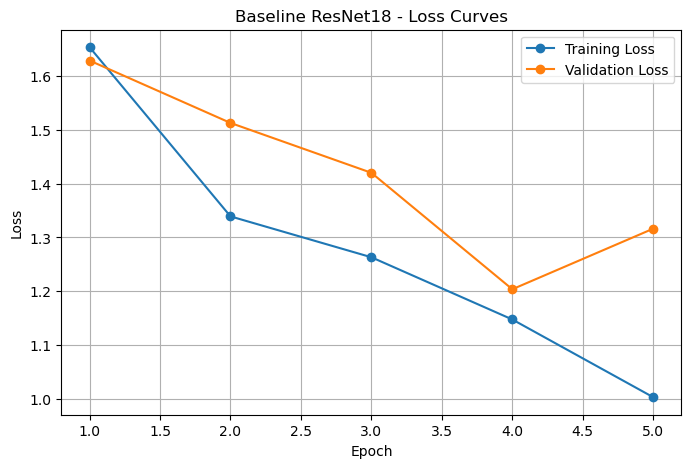

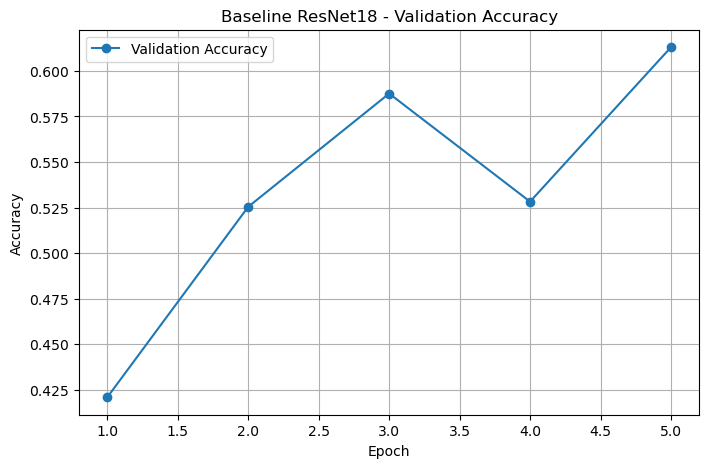

In [37]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(train_losses) + 1)

# Plot Loss Curves
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, train_losses, marker='o', label='Training Loss')
plt.plot(epochs_range, val_losses, marker='o', label='Validation Loss')
plt.title('Baseline ResNet18 - Loss Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# Plot Validation Accuracy Curve
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, val_accuracies, marker='o', label='Validation Accuracy')
plt.title('Baseline ResNet18 - Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

In [39]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# New data root
data_root = "/Users/bassma/Downloads/MedMentor/dataset_split"

# Augmented training transform
aug_train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation/Test transform stays clean
clean_eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# New datasets
aug_train_dataset = datasets.ImageFolder(root=f"{data_root}/train", transform=aug_train_transform)
aug_val_dataset = datasets.ImageFolder(root=f"{data_root}/val", transform=clean_eval_transform)
aug_test_dataset = datasets.ImageFolder(root=f"{data_root}/test", transform=clean_eval_transform)

# New dataloaders
batch_size = 16

aug_train_loader = DataLoader(aug_train_dataset, batch_size=batch_size, shuffle=True)
aug_val_loader = DataLoader(aug_val_dataset, batch_size=batch_size, shuffle=False)
aug_test_loader = DataLoader(aug_test_dataset, batch_size=batch_size, shuffle=False)

print("Augmented training pipeline created successfully.")
print("Train size:", len(aug_train_dataset))
print("Validation size:", len(aug_val_dataset))
print("Test size:", len(aug_test_dataset))

Augmented training pipeline created successfully.
Train size: 1649
Validation size: 354
Test size: 354


In [41]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from torchvision.models import ResNet18_Weights

# Fresh improved model
improved_model = models.resnet18(weights=ResNet18_Weights.DEFAULT)
improved_model.fc = nn.Linear(improved_model.fc.in_features, 9)
improved_model = improved_model.to(device)

# Loss and optimizer with weight decay
improved_criterion = nn.CrossEntropyLoss()
improved_optimizer = optim.Adam(improved_model.parameters(), lr=0.001, weight_decay=1e-4)

# Training settings
num_epochs_improved = 5
best_improved_val_accuracy = 0.0

improved_train_losses = []
improved_val_losses = []
improved_val_accuracies = []

improved_save_path = "/Users/bassma/Downloads/MedMentor/models/best_resnet18_augmented.pth"

for epoch in range(num_epochs_improved):
    print(f"\n===== IMPROVED EPOCH {epoch + 1}/{num_epochs_improved} =====")
    
    # Training phase
    improved_model.train()
    running_train_loss = 0.0
    
    for images, labels in aug_train_loader:
        images = images.to(device)
        labels = labels.to(device)
        
        improved_optimizer.zero_grad()
        outputs = improved_model(images)
        loss = improved_criterion(outputs, labels)
        loss.backward()
        improved_optimizer.step()
        
        running_train_loss += loss.item() * images.size(0)
    
    epoch_train_loss = running_train_loss / len(aug_train_dataset)
    improved_train_losses.append(epoch_train_loss)
    
    # Validation phase
    improved_model.eval()
    running_val_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for images, labels in aug_val_loader:
            images = images.to(device)
            labels = labels.to(device)
            
            outputs = improved_model(images)
            loss = improved_criterion(outputs, labels)
            
            running_val_loss += loss.item() * images.size(0)
            
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    
    epoch_val_loss = running_val_loss / len(aug_val_dataset)
    epoch_val_accuracy = correct / total
    
    improved_val_losses.append(epoch_val_loss)
    improved_val_accuracies.append(epoch_val_accuracy)
    
    print(f"Train Loss: {epoch_train_loss:.4f}")
    print(f"Validation Loss: {epoch_val_loss:.4f}")
    print(f"Validation Accuracy: {epoch_val_accuracy:.4f}")
    
    if epoch_val_accuracy > best_improved_val_accuracy:
        best_improved_val_accuracy = epoch_val_accuracy
        torch.save(improved_model.state_dict(), improved_save_path)
        print("Best improved model saved.")

print("\n===== IMPROVED TRAINING COMPLETE =====")
print("Best Improved Validation Accuracy:", best_improved_val_accuracy)
print("Best improved model saved at:")
print(improved_save_path)


===== IMPROVED EPOCH 1/5 =====
Train Loss: 1.6609
Validation Loss: 1.6210
Validation Accuracy: 0.5311
Best improved model saved.

===== IMPROVED EPOCH 2/5 =====
Train Loss: 1.4014
Validation Loss: 1.3672
Validation Accuracy: 0.5395
Best improved model saved.

===== IMPROVED EPOCH 3/5 =====
Train Loss: 1.3339
Validation Loss: 1.4376
Validation Accuracy: 0.5791
Best improved model saved.

===== IMPROVED EPOCH 4/5 =====
Train Loss: 1.2158
Validation Loss: 1.1060
Validation Accuracy: 0.6328
Best improved model saved.

===== IMPROVED EPOCH 5/5 =====
Train Loss: 1.1628
Validation Loss: 1.2371
Validation Accuracy: 0.5960

===== IMPROVED TRAINING COMPLETE =====
Best Improved Validation Accuracy: 0.632768361581921
Best improved model saved at:
/Users/bassma/Downloads/MedMentor/models/best_resnet18_augmented.pth


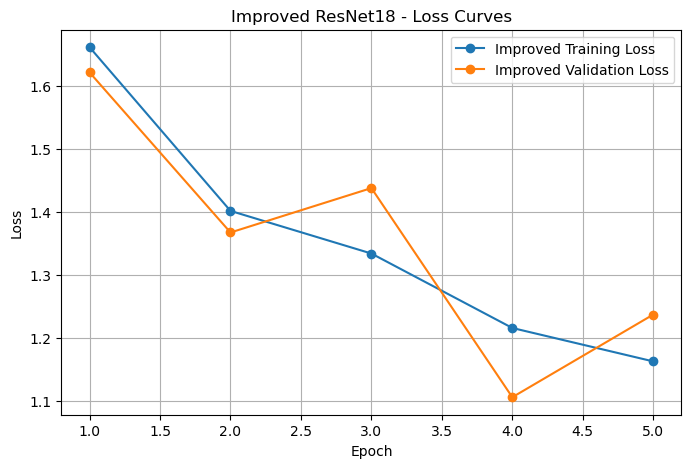

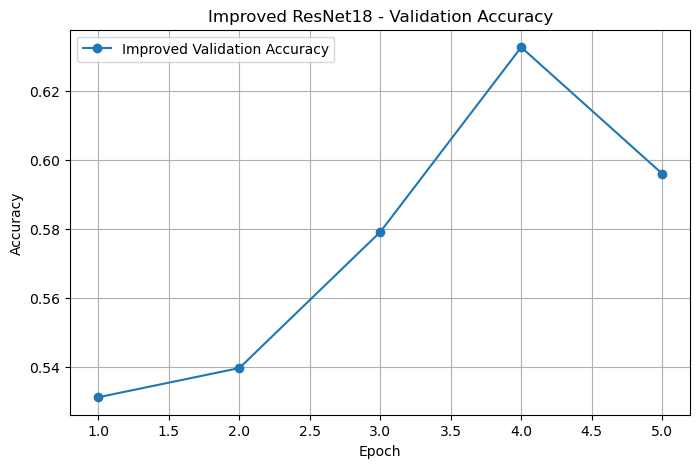

In [43]:
import matplotlib.pyplot as plt

improved_epochs_range = range(1, len(improved_train_losses) + 1)

# Improved Loss Curves
plt.figure(figsize=(8, 5))
plt.plot(improved_epochs_range, improved_train_losses, marker='o', label='Improved Training Loss')
plt.plot(improved_epochs_range, improved_val_losses, marker='o', label='Improved Validation Loss')
plt.title('Improved ResNet18 - Loss Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# Improved Validation Accuracy Curve
plt.figure(figsize=(8, 5))
plt.plot(improved_epochs_range, improved_val_accuracies, marker='o', label='Improved Validation Accuracy')
plt.title('Improved ResNet18 - Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

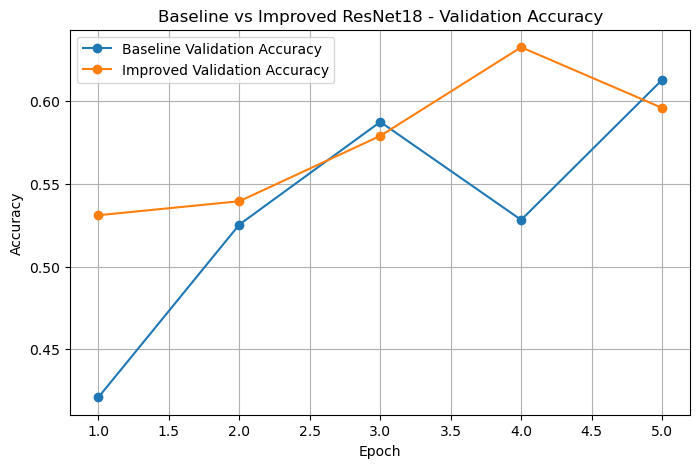

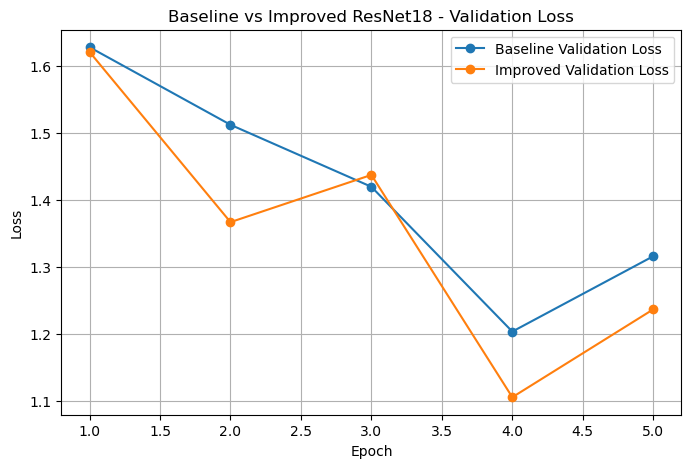

In [47]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(train_losses) + 1)

# Baseline vs Improved - Validation Accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, val_accuracies, marker='o', label='Baseline Validation Accuracy')
plt.plot(epochs_range, improved_val_accuracies, marker='o', label='Improved Validation Accuracy')
plt.title('Baseline vs Improved ResNet18 - Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Baseline vs Improved - Validation Loss
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, val_losses, marker='o', label='Baseline Validation Loss')
plt.plot(epochs_range, improved_val_losses, marker='o', label='Improved Validation Loss')
plt.title('Baseline vs Improved ResNet18 - Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [49]:
baseline_best_val = max(val_accuracies)
improved_best_val = max(improved_val_accuracies)

print("===== VALIDATION COMPARISON SUMMARY =====")
print(f"Baseline best validation accuracy: {baseline_best_val:.4f}")
print(f"Improved best validation accuracy: {improved_best_val:.4f}")
print(f"Absolute improvement: {improved_best_val - baseline_best_val:.4f}")

===== VALIDATION COMPARISON SUMMARY =====
Baseline best validation accuracy: 0.6130
Improved best validation accuracy: 0.6328
Absolute improvement: 0.0198


In [51]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from torchvision.models import ResNet18_Weights

# Fresh model for tuning experiment
tuned_model = models.resnet18(weights=ResNet18_Weights.DEFAULT)
tuned_model.fc = nn.Linear(tuned_model.fc.in_features, 9)
tuned_model = tuned_model.to(device)

# Loss and optimizer: same as improved experiment, but lower learning rate
tuned_criterion = nn.CrossEntropyLoss()
tuned_optimizer = optim.Adam(tuned_model.parameters(), lr=0.0001, weight_decay=1e-4)

# Training settings
num_epochs_tuned = 5
best_tuned_val_accuracy = 0.0

tuned_train_losses = []
tuned_val_losses = []
tuned_val_accuracies = []

tuned_save_path = "/Users/bassma/Downloads/MedMentor/models/best_resnet18_augmented_lr1e4.pth"

for epoch in range(num_epochs_tuned):
    print(f"\n===== TUNED EPOCH {epoch + 1}/{num_epochs_tuned} =====")
    
    # Training phase
    tuned_model.train()
    running_train_loss = 0.0
    
    for images, labels in aug_train_loader:
        images = images.to(device)
        labels = labels.to(device)
        
        tuned_optimizer.zero_grad()
        outputs = tuned_model(images)
        loss = tuned_criterion(outputs, labels)
        loss.backward()
        tuned_optimizer.step()
        
        running_train_loss += loss.item() * images.size(0)
    
    epoch_train_loss = running_train_loss / len(aug_train_dataset)
    tuned_train_losses.append(epoch_train_loss)
    
    # Validation phase
    tuned_model.eval()
    running_val_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for images, labels in aug_val_loader:
            images = images.to(device)
            labels = labels.to(device)
            
            outputs = tuned_model(images)
            loss = tuned_criterion(outputs, labels)
            
            running_val_loss += loss.item() * images.size(0)
            
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    
    epoch_val_loss = running_val_loss / len(aug_val_dataset)
    epoch_val_accuracy = correct / total
    
    tuned_val_losses.append(epoch_val_loss)
    tuned_val_accuracies.append(epoch_val_accuracy)
    
    print(f"Train Loss: {epoch_train_loss:.4f}")
    print(f"Validation Loss: {epoch_val_loss:.4f}")
    print(f"Validation Accuracy: {epoch_val_accuracy:.4f}")
    
    if epoch_val_accuracy > best_tuned_val_accuracy:
        best_tuned_val_accuracy = epoch_val_accuracy
        torch.save(tuned_model.state_dict(), tuned_save_path)
        print("Best tuned model saved.")

print("\n===== TUNED TRAINING COMPLETE =====")
print("Best Tuned Validation Accuracy:", best_tuned_val_accuracy)
print("Best tuned model saved at:")
print(tuned_save_path)


===== TUNED EPOCH 1/5 =====
Train Loss: 1.3182
Validation Loss: 1.0280
Validation Accuracy: 0.6469
Best tuned model saved.

===== TUNED EPOCH 2/5 =====
Train Loss: 0.8654
Validation Loss: 1.0158
Validation Accuracy: 0.6412

===== TUNED EPOCH 3/5 =====
Train Loss: 0.6752
Validation Loss: 1.0090
Validation Accuracy: 0.6582
Best tuned model saved.

===== TUNED EPOCH 4/5 =====
Train Loss: 0.5759
Validation Loss: 1.0029
Validation Accuracy: 0.6667
Best tuned model saved.

===== TUNED EPOCH 5/5 =====
Train Loss: 0.4458
Validation Loss: 0.9417
Validation Accuracy: 0.6497

===== TUNED TRAINING COMPLETE =====
Best Tuned Validation Accuracy: 0.6666666666666666
Best tuned model saved at:
/Users/bassma/Downloads/MedMentor/models/best_resnet18_augmented_lr1e4.pth


In [53]:
print("===== EXPERIMENT COMPARISON SUMMARY =====")
print(f"1. Baseline ResNet18                  -> Best Val Acc: {max(val_accuracies):.4f}")
print(f"2. Augmentation + Weight Decay       -> Best Val Acc: {max(improved_val_accuracies):.4f}")
print(f"3. Aug + Weight Decay + Lower LR     -> Best Val Acc: {max(tuned_val_accuracies):.4f}")

baseline_best = max(val_accuracies)
improved_best = max(improved_val_accuracies)
tuned_best = max(tuned_val_accuracies)

print("\n===== IMPROVEMENTS =====")
print(f"Improved - Baseline: {improved_best - baseline_best:.4f}")
print(f"Tuned - Baseline: {tuned_best - baseline_best:.4f}")
print(f"Tuned - Improved: {tuned_best - improved_best:.4f}")

===== EXPERIMENT COMPARISON SUMMARY =====
1. Baseline ResNet18                  -> Best Val Acc: 0.6130
2. Augmentation + Weight Decay       -> Best Val Acc: 0.6328
3. Aug + Weight Decay + Lower LR     -> Best Val Acc: 0.6667

===== IMPROVEMENTS =====
Improved - Baseline: 0.0198
Tuned - Baseline: 0.0537
Tuned - Improved: 0.0339


In [55]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Smaller image size for simple CNN baseline
cnn_data_root = "/Users/bassma/Downloads/MedMentor/dataset_split"

cnn_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

cnn_train_dataset = datasets.ImageFolder(root=f"{cnn_data_root}/train", transform=cnn_transform)
cnn_val_dataset = datasets.ImageFolder(root=f"{cnn_data_root}/val", transform=cnn_transform)
cnn_test_dataset = datasets.ImageFolder(root=f"{cnn_data_root}/test", transform=cnn_transform)

cnn_batch_size = 16

cnn_train_loader = DataLoader(cnn_train_dataset, batch_size=cnn_batch_size, shuffle=True)
cnn_val_loader = DataLoader(cnn_val_dataset, batch_size=cnn_batch_size, shuffle=False)
cnn_test_loader = DataLoader(cnn_test_dataset, batch_size=cnn_batch_size, shuffle=False)

print("CNN baseline data pipeline created.")
print("Train size:", len(cnn_train_dataset))
print("Validation size:", len(cnn_val_dataset))
print("Test size:", len(cnn_test_dataset))
print("Train batches:", len(cnn_train_loader))
print("Validation batches:", len(cnn_val_loader))
print("Test batches:", len(cnn_test_loader))

CNN baseline data pipeline created.
Train size: 1649
Validation size: 354
Test size: 354
Train batches: 104
Validation batches: 23
Test batches: 23


In [57]:
import torch
import torch.nn as nn

class SimpleCNN(nn.Module):
    def __init__(self, num_classes=9):
        super(SimpleCNN, self).__init__()
        
        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            
            # Block 2
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 32 * 32, 128),   # because input is 128x128 -> after 2 poolings becomes 32x32
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )
    
    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

cnn_model = SimpleCNN(num_classes=9).to(device)

print(cnn_model)
print("\nCNN baseline model created successfully.")

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=65536, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=9, bias=True)
  )
)

CNN baseline model created successfully.


In [59]:
import torch.optim as optim

# Loss and optimizer for CNN baseline
cnn_criterion = nn.CrossEntropyLoss()
cnn_optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)

# Training settings
num_epochs_cnn = 5
best_cnn_val_accuracy = 0.0

cnn_train_losses = []
cnn_val_losses = []
cnn_val_accuracies = []

cnn_save_path = "/Users/bassma/Downloads/MedMentor/models/best_simple_cnn.pth"

for epoch in range(num_epochs_cnn):
    print(f"\n===== CNN EPOCH {epoch + 1}/{num_epochs_cnn} =====")
    
    # Training phase
    cnn_model.train()
    running_train_loss = 0.0
    
    for images, labels in cnn_train_loader:
        images = images.to(device)
        labels = labels.to(device)
        
        cnn_optimizer.zero_grad()
        outputs = cnn_model(images)
        loss = cnn_criterion(outputs, labels)
        loss.backward()
        cnn_optimizer.step()
        
        running_train_loss += loss.item() * images.size(0)
    
    epoch_train_loss = running_train_loss / len(cnn_train_dataset)
    cnn_train_losses.append(epoch_train_loss)
    
    # Validation phase
    cnn_model.eval()
    running_val_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for images, labels in cnn_val_loader:
            images = images.to(device)
            labels = labels.to(device)
            
            outputs = cnn_model(images)
            loss = cnn_criterion(outputs, labels)
            
            running_val_loss += loss.item() * images.size(0)
            
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    
    epoch_val_loss = running_val_loss / len(cnn_val_dataset)
    epoch_val_accuracy = correct / total
    
    cnn_val_losses.append(epoch_val_loss)
    cnn_val_accuracies.append(epoch_val_accuracy)
    
    print(f"Train Loss: {epoch_train_loss:.4f}")
    print(f"Validation Loss: {epoch_val_loss:.4f}")
    print(f"Validation Accuracy: {epoch_val_accuracy:.4f}")
    
    if epoch_val_accuracy > best_cnn_val_accuracy:
        best_cnn_val_accuracy = epoch_val_accuracy
        torch.save(cnn_model.state_dict(), cnn_save_path)
        print("Best CNN model saved.")

print("\n===== CNN TRAINING COMPLETE =====")
print("Best CNN Validation Accuracy:", best_cnn_val_accuracy)
print("Best CNN model saved at:")
print(cnn_save_path)


===== CNN EPOCH 1/5 =====
Train Loss: 1.8814
Validation Loss: 1.7181
Validation Accuracy: 0.3446
Best CNN model saved.

===== CNN EPOCH 2/5 =====
Train Loss: 1.5063
Validation Loss: 1.5097
Validation Accuracy: 0.4972
Best CNN model saved.

===== CNN EPOCH 3/5 =====
Train Loss: 1.3154
Validation Loss: 1.4458
Validation Accuracy: 0.5339
Best CNN model saved.

===== CNN EPOCH 4/5 =====
Train Loss: 1.1489
Validation Loss: 1.5182
Validation Accuracy: 0.5254

===== CNN EPOCH 5/5 =====
Train Loss: 1.0021
Validation Loss: 1.4510
Validation Accuracy: 0.5452
Best CNN model saved.

===== CNN TRAINING COMPLETE =====
Best CNN Validation Accuracy: 0.5451977401129944
Best CNN model saved at:
/Users/bassma/Downloads/MedMentor/models/best_simple_cnn.pth


In [61]:
print("===== FINAL MODEL COMPARISON =====")
print(f"1. Simple CNN Baseline                  -> Best Val Acc: {max(cnn_val_accuracies):.4f}")
print(f"2. ResNet18 Baseline                   -> Best Val Acc: {max(val_accuracies):.4f}")
print(f"3. ResNet18 + Aug + Weight Decay       -> Best Val Acc: {max(improved_val_accuracies):.4f}")
print(f"4. ResNet18 + Aug + WD + Lower LR      -> Best Val Acc: {max(tuned_val_accuracies):.4f}")

cnn_best = max(cnn_val_accuracies)
resnet_base_best = max(val_accuracies)
resnet_improved_best = max(improved_val_accuracies)
resnet_tuned_best = max(tuned_val_accuracies)

print("\n===== KEY TAKEAWAYS =====")
print(f"ResNet18 Baseline - CNN Baseline: {resnet_base_best - cnn_best:.4f}")
print(f"ResNet18 Improved - CNN Baseline: {resnet_improved_best - cnn_best:.4f}")
print(f"ResNet18 Tuned - CNN Baseline: {resnet_tuned_best - cnn_best:.4f}")
print(f"Tuned ResNet18 - Baseline ResNet18: {resnet_tuned_best - resnet_base_best:.4f}")

===== FINAL MODEL COMPARISON =====
1. Simple CNN Baseline                  -> Best Val Acc: 0.5452
2. ResNet18 Baseline                   -> Best Val Acc: 0.6130
3. ResNet18 + Aug + Weight Decay       -> Best Val Acc: 0.6328
4. ResNet18 + Aug + WD + Lower LR      -> Best Val Acc: 0.6667

===== KEY TAKEAWAYS =====
ResNet18 Baseline - CNN Baseline: 0.0678
ResNet18 Improved - CNN Baseline: 0.0876
ResNet18 Tuned - CNN Baseline: 0.1215
Tuned ResNet18 - Baseline ResNet18: 0.0537


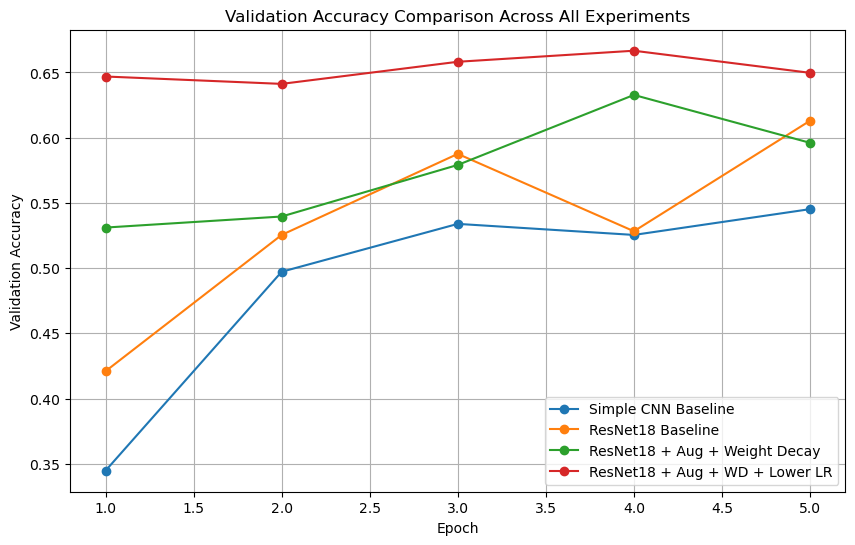

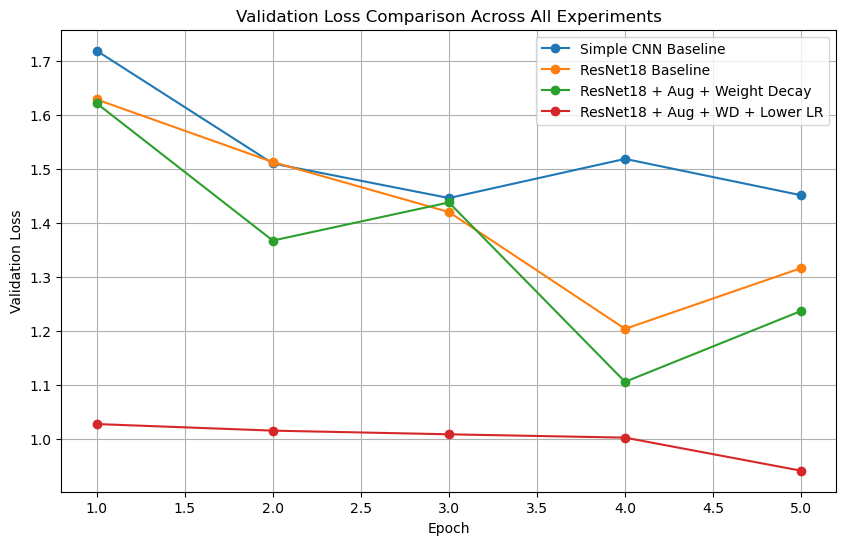

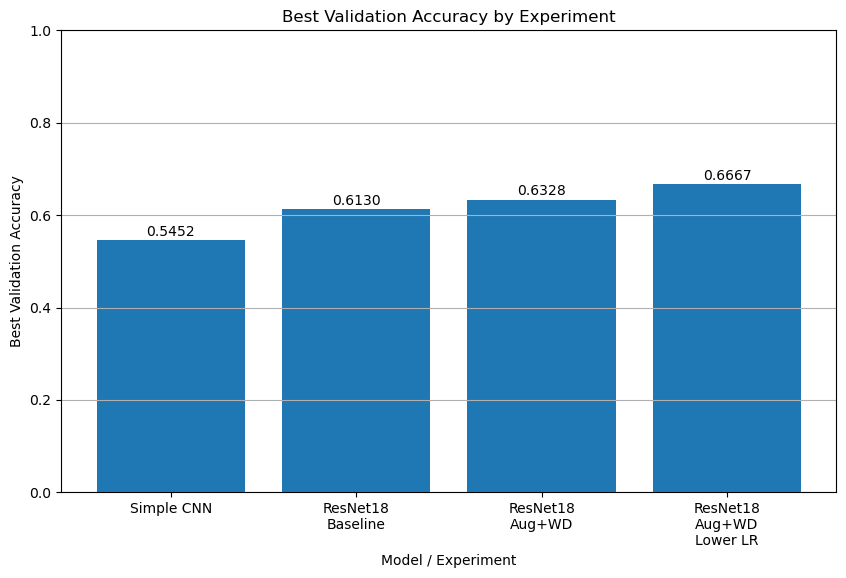

In [63]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(val_accuracies) + 1)

# -----------------------------
# 1) Validation Accuracy Curves
# -----------------------------
plt.figure(figsize=(10, 6))
plt.plot(epochs_range, cnn_val_accuracies, marker='o', label='Simple CNN Baseline')
plt.plot(epochs_range, val_accuracies, marker='o', label='ResNet18 Baseline')
plt.plot(epochs_range, improved_val_accuracies, marker='o', label='ResNet18 + Aug + Weight Decay')
plt.plot(epochs_range, tuned_val_accuracies, marker='o', label='ResNet18 + Aug + WD + Lower LR')

plt.title('Validation Accuracy Comparison Across All Experiments')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# -------------------------
# 2) Validation Loss Curves
# -------------------------
plt.figure(figsize=(10, 6))
plt.plot(epochs_range, cnn_val_losses, marker='o', label='Simple CNN Baseline')
plt.plot(epochs_range, val_losses, marker='o', label='ResNet18 Baseline')
plt.plot(epochs_range, improved_val_losses, marker='o', label='ResNet18 + Aug + Weight Decay')
plt.plot(epochs_range, tuned_val_losses, marker='o', label='ResNet18 + Aug + WD + Lower LR')

plt.title('Validation Loss Comparison Across All Experiments')
plt.xlabel('Epoch')
plt.ylabel('Validation Loss')
plt.legend()
plt.grid(True)
plt.show()

# ------------------------------------
# 3) Best Validation Accuracy Bar Plot
# ------------------------------------
model_names = [
    'Simple CNN',
    'ResNet18\nBaseline',
    'ResNet18\nAug+WD',
    'ResNet18\nAug+WD\nLower LR'
]

best_val_accs = [
    max(cnn_val_accuracies),
    max(val_accuracies),
    max(improved_val_accuracies),
    max(tuned_val_accuracies)
]

plt.figure(figsize=(10, 6))
plt.bar(model_names, best_val_accs)
plt.title('Best Validation Accuracy by Experiment')
plt.xlabel('Model / Experiment')
plt.ylabel('Best Validation Accuracy')
plt.ylim(0, 1)

for i, acc in enumerate(best_val_accs):
    plt.text(i, acc + 0.01, f"{acc:.4f}", ha='center')

plt.grid(True, axis='y')
plt.show()

In [65]:
import torch
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from torchvision import models
import torch.nn as nn

# Rebuild the tuned model architecture
final_tuned_model = models.resnet18(weights=None)
final_tuned_model.fc = nn.Linear(final_tuned_model.fc.in_features, 9)

# Load the best tuned weights
final_tuned_model.load_state_dict(
    torch.load(
        "/Users/bassma/Downloads/MedMentor/models/best_resnet18_augmented_lr1e4.pth",
        map_location=device
    )
)

final_tuned_model = final_tuned_model.to(device)
final_tuned_model.eval()

all_tuned_preds = []
all_tuned_true = []

with torch.no_grad():
    for images, labels in aug_test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = final_tuned_model(images)
        _, preds = torch.max(outputs, 1)

        all_tuned_preds.extend(preds.cpu().numpy())
        all_tuned_true.extend(labels.cpu().numpy())

# Test Accuracy
tuned_test_accuracy = accuracy_score(all_tuned_true, all_tuned_preds)
print("===== TUNED MODEL TEST ACCURACY =====")
print("Tuned Test Accuracy:", tuned_test_accuracy)

# Classification Report
print("\n===== TUNED MODEL CLASSIFICATION REPORT =====")
print(classification_report(all_tuned_true, all_tuned_preds, target_names=class_names))

# Confusion Matrix
print("\n===== TUNED MODEL CONFUSION MATRIX =====")
tuned_cm = confusion_matrix(all_tuned_true, all_tuned_preds)
print(tuned_cm)

===== TUNED MODEL TEST ACCURACY =====
Tuned Test Accuracy: 0.652542372881356

===== TUNED MODEL CLASSIFICATION REPORT =====
                            precision    recall  f1-score   support

         actinic keratosis       0.40      0.20      0.27        20
      basal cell carcinoma       0.69      0.71      0.70        59
            dermatofibroma       0.85      0.69      0.76        16
                  melanoma       0.63      0.71      0.67        68
                     nevus       0.50      0.66      0.57        56
pigmented benign keratosis       0.76      0.76      0.76        72
      seborrheic keratosis       0.00      0.00      0.00        12
   squamous cell carcinoma       0.74      0.47      0.57        30
           vascular lesion       0.74      0.95      0.83        21

                  accuracy                           0.65       354
                 macro avg       0.59      0.57      0.57       354
              weighted avg       0.64      0.65      0.64 

In [67]:
import torch
import torch.nn as nn
from torchvision import models
import torch.nn.functional as F
from PIL import Image

# Final selected model path
final_model_path = "/Users/bassma/Downloads/MedMentor/models/best_resnet18_augmented_lr1e4.pth"

# Rebuild the final model architecture
final_predict_model = models.resnet18(weights=None)
final_predict_model.fc = nn.Linear(final_predict_model.fc.in_features, 9)

# Load final tuned weights
final_predict_model.load_state_dict(torch.load(final_model_path, map_location=device))
final_predict_model = final_predict_model.to(device)
final_predict_model.eval()

print("Final tuned model loaded successfully.")
print("Using model file:")
print(final_model_path)

Final tuned model loaded successfully.
Using model file:
/Users/bassma/Downloads/MedMentor/models/best_resnet18_augmented_lr1e4.pth


In [69]:
def predict_skin_lesion_final(image_path, model, class_names, transform, device):
    image = Image.open(image_path).convert("RGB")
    image_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(image_tensor)
        probabilities = F.softmax(outputs, dim=1)[0]

    top3_probs, top3_indices = torch.topk(probabilities, 3)

    prediction_main = class_names[top3_indices[0].item()]
    confidence = top3_probs[0].item()

    top3 = []
    for prob, idx in zip(top3_probs, top3_indices):
        top3.append([
            class_names[idx.item()],
            round(prob.item(), 4)
        ])

    result = {
        "prediction_main": prediction_main,
        "confidence": round(confidence, 4),
        "top3": top3
    }

    return result

print("Final prediction function is ready.")

Final prediction function is ready.


In [71]:
from pathlib import Path

real_test_folder = Path("/Users/bassma/Downloads/MedMentor/dataset_split/test")

sample_final_test_image = None

for class_folder in sorted(real_test_folder.iterdir()):
    if class_folder.is_dir():
        for image_file in sorted(class_folder.iterdir()):
            if image_file.is_file() and not image_file.name.startswith("."):
                sample_final_test_image = str(image_file)
                break
    if sample_final_test_image is not None:
        break

print("Testing final tuned model on image:")
print(sample_final_test_image)

final_result = predict_skin_lesion_final(
    image_path=sample_final_test_image,
    model=final_predict_model,
    class_names=class_names,
    transform=clean_eval_transform,
    device=device
)

print("\nFinal prediction result:")
print(final_result)

Testing final tuned model on image:
/Users/bassma/Downloads/MedMentor/dataset_split/test/actinic keratosis/ISIC_0025605.jpg

Final prediction result:
{'prediction_main': 'squamous cell carcinoma', 'confidence': 0.4818, 'top3': [['squamous cell carcinoma', 0.4818], ['pigmented benign keratosis', 0.3203], ['nevus', 0.0859]]}


In [73]:
def predict_skin_lesion_final_v3(image_path, model, class_names, transform, device):
    image = Image.open(image_path).convert("RGB")
    image_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(image_tensor)
        probabilities = F.softmax(outputs, dim=1)[0]

    top3_probs, top3_indices = torch.topk(probabilities, 3)

    prediction_main = class_names[top3_indices[0].item()]
    confidence_value = top3_probs[0].item()

    top3 = []
    for prob, idx in zip(top3_probs, top3_indices):
        top3.append({
            "class_name": class_names[idx.item()],
            "probability": f"{prob.item() * 100:.2f}%"
        })

    result = {
        "prediction_main": prediction_main,
        "confidence": f"{confidence_value * 100:.2f}%",
        "top3": top3
    }

    return result

print("Final prediction function with percentage formatting is ready.")

Final prediction function with percentage formatting is ready.


In [75]:
final_result_v3 = predict_skin_lesion_final_v3(
    image_path=sample_final_test_image,
    model=final_predict_model,
    class_names=class_names,
    transform=clean_eval_transform,
    device=device
)

print("Final prediction result with percentages:")
print(final_result_v3)

Final prediction result with percentages:
{'prediction_main': 'squamous cell carcinoma', 'confidence': '48.18%', 'top3': [{'class_name': 'squamous cell carcinoma', 'probability': '48.18%'}, {'class_name': 'pigmented benign keratosis', 'probability': '32.03%'}, {'class_name': 'nevus', 'probability': '8.59%'}]}
